In [1]:
import tensorflow as tf; print('TensorFlow:', tf.__version__); print('GPUs:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPUs: []


## 1.2 Dataset audit

Scan every file for image metadata and a SHA-256 content hash. Display class counts, size statistics, unreadable files and exact duplicates below; no CSV files are written.


In [2]:
from pathlib import Path
import hashlib
import pandas as pd
from PIL import Image
from IPython.display import display

# The notebook runs from the project directory.
dataset_root = (Path.cwd() / "cashbowman" / "ai-generated-images-vs-real-images"
                / "versions" / "1")
class_folders = {"AI-generated": "AiArtData", "Real": "RealArt"}

def sha256_file(path):
    """Hash file contents in chunks, so large files do not fill memory."""
    digest = hashlib.sha256()
    with path.open("rb") as image_file:
        for chunk in iter(lambda: image_file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def inspect_file(path, dataset_root, label):
    record = {
        "path": path.relative_to(dataset_root).as_posix(),
        "class": label,
        "file_size_bytes": "",
        "width": "",
        "height": "",
        "colour_mode": "",
        "format": "",
        "sha256": "",
        "unreadable": False,
        "error": "",
        "duplicate_of": "",
    }
    try:
        record["file_size_bytes"] = path.stat().st_size
        record["sha256"] = sha256_file(path)
        # verify() checks file integrity; load() also checks pixel decoding.
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            image.load()
            record.update(
                width=image.width,
                height=image.height,
                colour_mode=image.mode,
                format=image.format,
            )
    except Exception as error:
        # Keep the failed file in the audit instead of silently skipping it.
        record["unreadable"] = True
        record["error"] = f"{type(error).__name__}: {error}"
    return record

In [3]:
# Scan recursively because the class folder names are repeated inside the download.
records = []
first_seen = {}
for label, folder in class_folders.items():
    class_root = dataset_root / folder
    if not class_root.is_dir():
        raise FileNotFoundError(f"Missing dataset folder: {class_root}")
    paths = sorted(path for path in class_root.rglob("*") if path.is_file())
    if not paths:
        raise ValueError(f"No files found in {class_root}")
    for path in paths:
        row = inspect_file(path, dataset_root, label)
        content_hash = row["sha256"]
        if content_hash:
            if content_hash in first_seen:
                row["duplicate_of"] = first_seen[content_hash]
            else:
                first_seen[content_hash] = row["path"]
        records.append(row)

audit_df = pd.DataFrame(records)
for column in ["width", "height", "file_size_bytes"]:
    audit_df[column] = pd.to_numeric(audit_df[column], errors="coerce").astype("Int64")
print(f"Audited {len(audit_df)} files. The full per-image table is stored in audit_df.")
display(audit_df)


Audited 975 files. The full per-image table is stored in audit_df.


,path,class,file_size_bytes,width,height,colour_mode,format,sha256,unreadable,error,duplicate_of
0,AiArtData/AiArtData/-how-important-people-from...,AI-generated,97136,880,440,RGB,JPEG,410f52ab558884eba3b6b271b4f5ade076f6dc06adbf14...,False,,
1,AiArtData/AiArtData/-s-fluffy-fur-and-round-fe...,AI-generated,329446,2940,1960,RGB,JPEG,e31692a1b6ac7ff0754ea8717ad51e1cbed6267982bace...,False,,
2,AiArtData/AiArtData/-using-generative-ai-techn...,AI-generated,267045,1067,1690,RGB,JPEG,e90cbc6e6199b9f622295d61ef0913f2f64f0544c2f650...,False,,
3,AiArtData/AiArtData/-yellow-kimono-with-a-gold...,AI-generated,89671,800,800,RGB,JPEG,ea4b6260faac11d4914e56c123d87b97c692ab2c3802fa...,False,,
4,AiArtData/AiArtData/.amazonaws.com2Fpublic2Fim...,AI-generated,52677,600,480,RGB,JPEG,3009ba845a440f74016286b0603c244c681a93e1f4a14f...,False,,
...,...,...,...,...,...,...,...,...,...,...,...
970,RealArt/RealArt/Women-clothing-Kenya-East-Afri...,Real,267179,1600,836,RGB,JPEG,e1e3f9dca6ace7a72f6ade3e73c9c76c7adde58a11707e...,False,,
971,RealArt/RealArt/Worlds-15-Most-Iconic-Portrait...,Real,70700,552,800,RGB,JPEG,893f967dc76df6678f85027dc636941ffb41dae9bdd0d1...,False,,
972,RealArt/RealArt/WR202206_GiraffeTranslocation_...,Real,390161,1200,630,RGB,JPEG,99e573355842fdd6919b832593f7e9429ca98ec13bc313...,False,,
973,RealArt/RealArt/XaHpf_z51huQS_JPHs-jkPhBp0dLlx...,Real,636250,2048,1365,RGB,JPEG,c1ee99f18fe1b880896cacaaf1e15e01085aec08fe1b06...,False,,


In [4]:
# Counts and quality checks for each class.
counts = audit_df.groupby("class").agg(
    files=("path", "size"),
    readable_images=("unreadable", lambda values: (~values).sum()),
    corrupt_or_unreadable=("unreadable", "sum"),
    duplicate_files=("duplicate_of", lambda values: values.ne("").sum()),
)
print("Counts per class (duplicates count additional copies beyond the first):")
display(counts)

# Missing dimensions from unreadable files are excluded automatically.
# File-size statistics include every file whose size could be read.
size_stats = audit_df.groupby("class")[["width", "height", "file_size_bytes"]].agg(
    ["min", "median", "max"]
)
print("Image dimensions in pixels and file sizes in bytes:")
display(size_stats)

unreadable_files = audit_df.loc[audit_df["unreadable"], ["path", "class", "error"]]
print(f"Corrupt or unreadable files: {len(unreadable_files)}")
display(unreadable_files)

# Show both the original and every extra copy in each duplicate group.
duplicate_images = audit_df.loc[
    audit_df["sha256"].ne("") & audit_df["sha256"].duplicated(keep=False),
    ["path", "class", "sha256", "duplicate_of"],
].sort_values("sha256")
print(f"Exact duplicate groups: {duplicate_images['sha256'].nunique()}")
print(f"Additional duplicate files: {audit_df['duplicate_of'].ne('').sum()}")
with pd.option_context("display.max_colwidth", None):
    display(duplicate_images)
print("SHA-256 detects identical file bytes; visually similar images may have different hashes.")


Counts per class (duplicates count additional copies beyond the first):


,files,readable_images,corrupt_or_unreadable,duplicate_files
class,,,,
AI-generated,539,539,0,1
Real,436,436,0,0


Image dimensions in pixels and file sizes in bytes:


width               height              file_size_bytes  \
               min  median   max    min median   max             min   
class                                                                  
AI-generated   225  1024.0  6000    135  800.0  4001           11738   
Real           183   920.0  8495    158  720.0  7091           11311   

                                  
                median       max  
class                             
AI-generated  199760.0   5626183  
Real          144840.0  10195352

Corrupt or unreadable files: 0


,path,class,error


Exact duplicate groups: 1
Additional duplicate files: 1


,path,class,sha256,duplicate_of
346,AiArtData/AiArtData/image33.jpg,AI-generated,f3268a4fc0477b2f3d9728f118afe32bf5196c3b476def53e34229672f77dc97,
347,AiArtData/AiArtData/image34.jpg,AI-generated,f3268a4fc0477b2f3d9728f118afe32bf5196c3b476def53e34229672f77dc97,AiArtData/AiArtData/image33.jpg


SHA-256 detects identical file bytes; visually similar images may have different hashes.


## 1.3 Visual EDA

The following figures use the readable images audited in Task 1.2. Histograms include all readable files, including the exact duplicate; only the sample grid excludes repeated hashes.


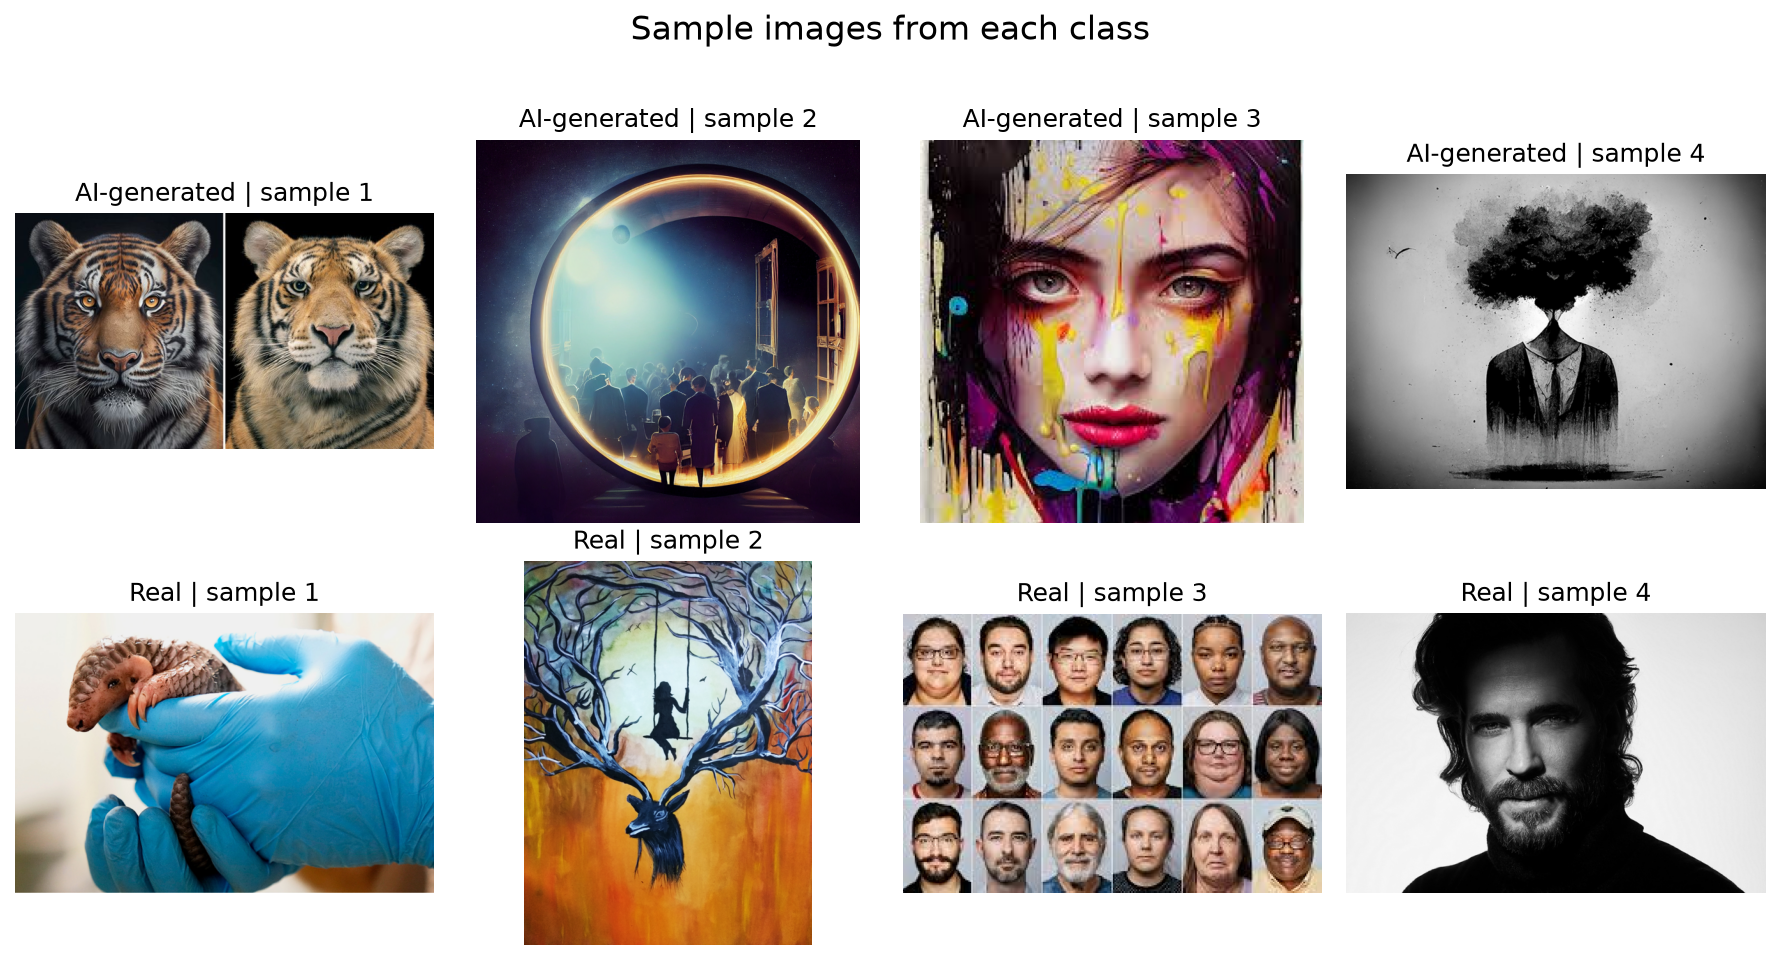

In [5]:
import io
import numpy as np
import matplotlib.pyplot as plt
from PIL import ImageOps
from IPython.display import Image as NotebookImage

# Reuse the full image audit from Task 1.2; do not modify the dataset.
eda_df = audit_df.loc[~audit_df["unreadable"]].copy()
class_labels = list(class_folders)
colours = {"AI-generated": "#3769A8", "Real": "#C47830"}
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12})

def show_figure(fig):
    # Embed the PNG in the notebook without creating output folders.
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(NotebookImage(data=buffer.getvalue()))

# A fixed seed makes the sample grid reproducible. Use distinct file hashes here.
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for row_index, label in enumerate(class_labels):
    candidates = eda_df.loc[eda_df["class"] == label].drop_duplicates("sha256")
    samples = candidates.sample(n=min(4, len(candidates)), random_state=42)
    for column_index, (_, sample) in enumerate(samples.iterrows()):
        ax = axes[row_index, column_index]
        with Image.open(dataset_root / sample["path"]) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            image.thumbnail((600, 600))
            ax.imshow(image)
        ax.set_title(f"{label} | sample {column_index + 1}")
        ax.axis("off")
    for ax in axes[row_index, len(samples):]:
        ax.axis("off")
fig.suptitle("Sample images from each class", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.95))
show_figure(fig)


**Figure 1. Sample grid with four images from each class, selected using random seed 42 and displayed without stretching.**

The AI-generated samples include animals, a stylized portrait and surreal scenes, while the Real samples include photographs, a painted scene and a collage. The painted image in the Real class shows that artistic style alone does not determine the folder label. These eight examples illustrate variation but are too few to establish the quality of all labels.


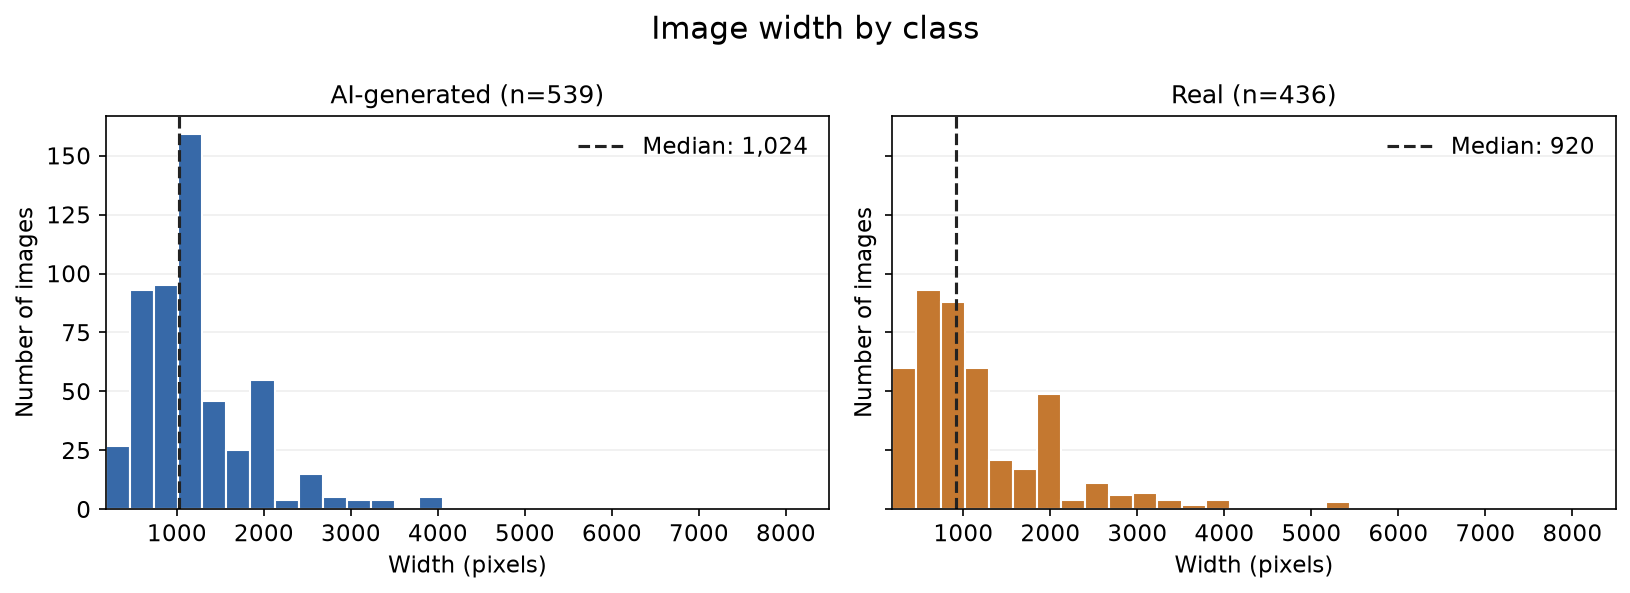

In [6]:
def plot_class_histograms(column, title, x_label, scale=1):
    # Both classes use identical bin edges and axis limits for comparison.
    all_values = eda_df[column].dropna().to_numpy(dtype=float) / scale
    bin_edges = np.histogram_bin_edges(all_values, bins=30)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
    for ax, label in zip(axes, class_labels):
        values = eda_df.loc[eda_df["class"] == label, column].dropna().to_numpy(dtype=float) / scale
        median = np.median(values)
        ax.hist(values, bins=bin_edges, color=colours[label], edgecolor="white")
        ax.axvline(median, color="#222222", linestyle="--", linewidth=1.5,
                   label=f"Median: {median:,.2f}" if scale != 1 else f"Median: {median:,.0f}")
        ax.set_title(f"{label} (n={len(values)})")
        ax.set_xlabel(x_label)
        ax.set_ylabel("Number of images")
        ax.set_xlim(bin_edges[0], bin_edges[-1])
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
        ax.legend(frameon=False)
    fig.suptitle(title, fontsize=15)
    fig.tight_layout()
    show_figure(fig)

plot_class_histograms("width", "Image width by class", "Width (pixels)")


**Figure 2. Width histograms per class, using 30 shared bins and matching axes; dashed lines mark the medians.**

Both width distributions are right-skewed, with many smaller images and a few very wide images. The AI-generated class has a median width of 1,024 pixels compared with 920 pixels for Real, so inputs need a consistent target size before batching.


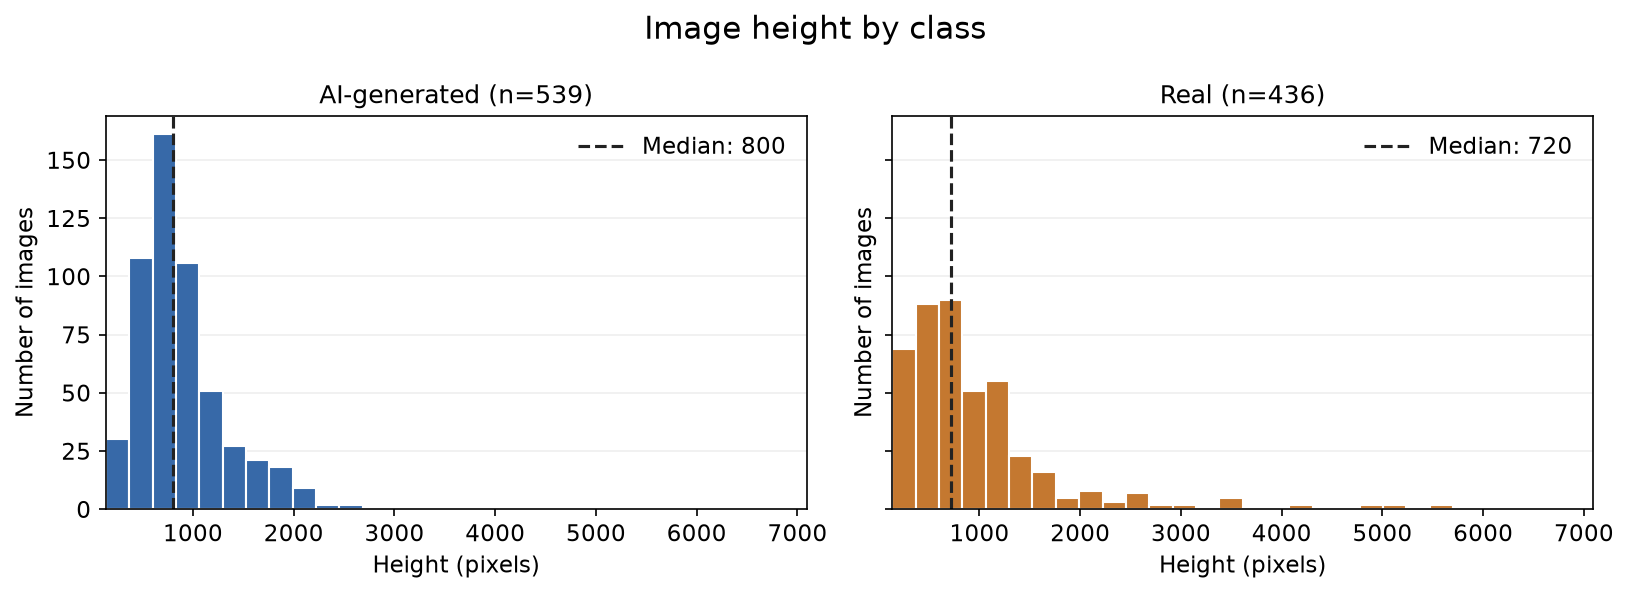

In [7]:
plot_class_histograms("height", "Image height by class", "Height (pixels)")


**Figure 3. Height histograms per class, using 30 shared bins and matching axes; dashed lines mark the medians.**

Image heights also have long right tails, especially in the Real class. Median heights are 800 pixels for AI-generated and 720 pixels for Real, and the variation in both dimensions means resizing should handle aspect ratio explicitly.


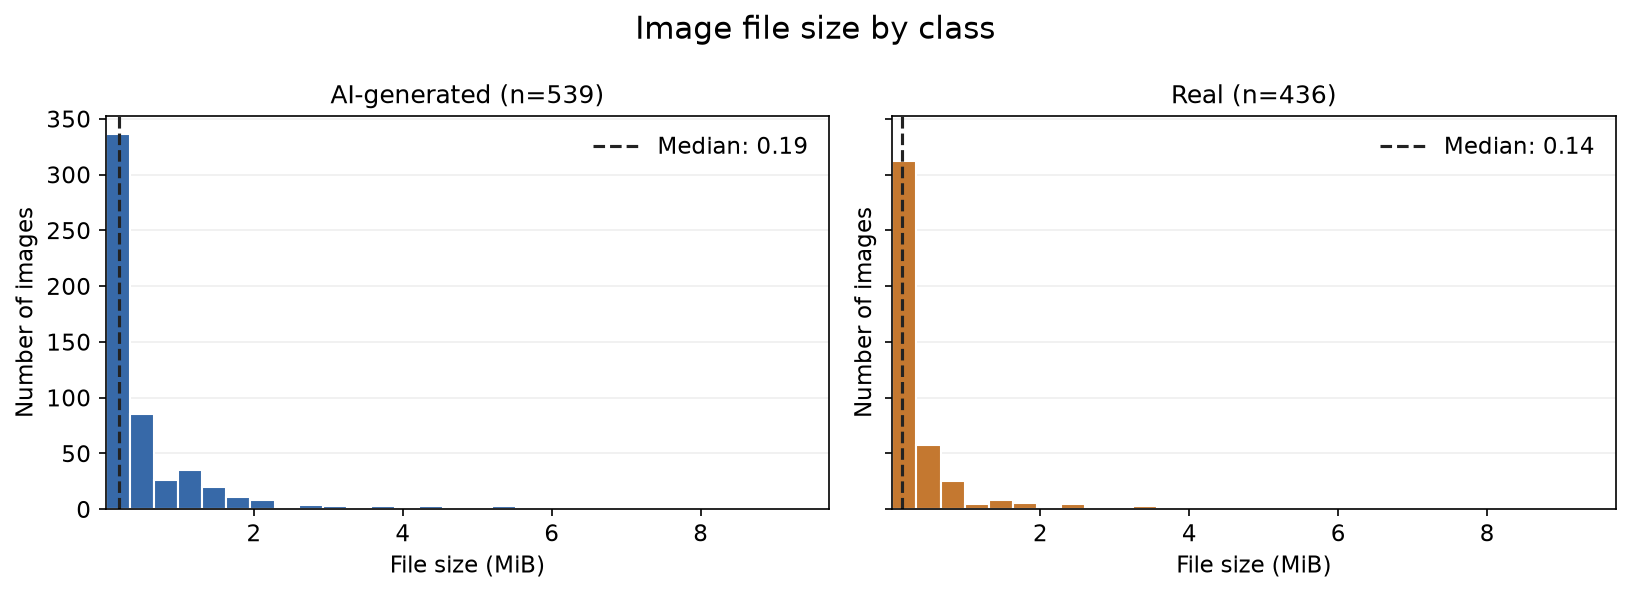

In [8]:
plot_class_histograms("file_size_bytes", "Image file size by class", "File size (MiB)", scale=1024 ** 2)


**Figure 4. File-size histograms per class in MiB, using 30 shared bins and matching axes; dashed lines mark the medians.**

Both classes have strongly right-skewed file-size distributions, with medians of about 0.19 MiB for AI-generated and 0.14 MiB for Real. A few large files extend the tails, so median size describes a typical file better than the maximum; file size alone does not prove whether an image is AI-generated.


## 2.1 Input pipeline

I use a reproducible, stratified 70/15/15 train/validation/test split after excluding unreadable files and removing exact duplicate hashes. The split lists retain relative paths, class labels and SHA-256 hashes, and are saved in `splits/` so later experiments use the same images; overlapping hashes are explicitly rejected.

Images are decoded with Pillow inside `tf.numpy_function` to support this dataset's JPEG, PNG, WebP and GIF files, normalized to RGB, and resized with `tf.image.resize_with_pad` to 128 x 128 pixels. Padding preserves aspect ratio instead of stretching: empty space becomes black borders, while 128 pixels keeps CPU training practical at the cost of some fine detail. Only the first frame of animated files is used, and EXIF orientation is applied consistently.

The pipeline reads each split CSV, decodes/resizes in parallel, caches the resized images in memory, shuffles only training data, batches 16 images, applies random flip/rotation/zoom/contrast only to training batches, and prefetches the next batch. Caching occurs before augmentation, so fresh training transformations remain possible each epoch; validation and test preprocessing is deterministic. Models receive float pixels in [0,255] and contain their own normalization layer.

Model checkpoints, histories, cached test predictions and tuner states are saved under the Git-ignored `artifacts/` directory. Install the pinned dependencies from `requirements-task2.txt` when reproducing the notebook; Task 2.5 deliberately stops if test predictions already exist, preventing accidental repeat evaluation of this experiment.


class,AI-generated,Real
split,,
test,81,66
train,376,305
validation,81,65


D:\Mamoon\Code\MLOps-A2\.venv\Lib\site-packages\PIL\Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


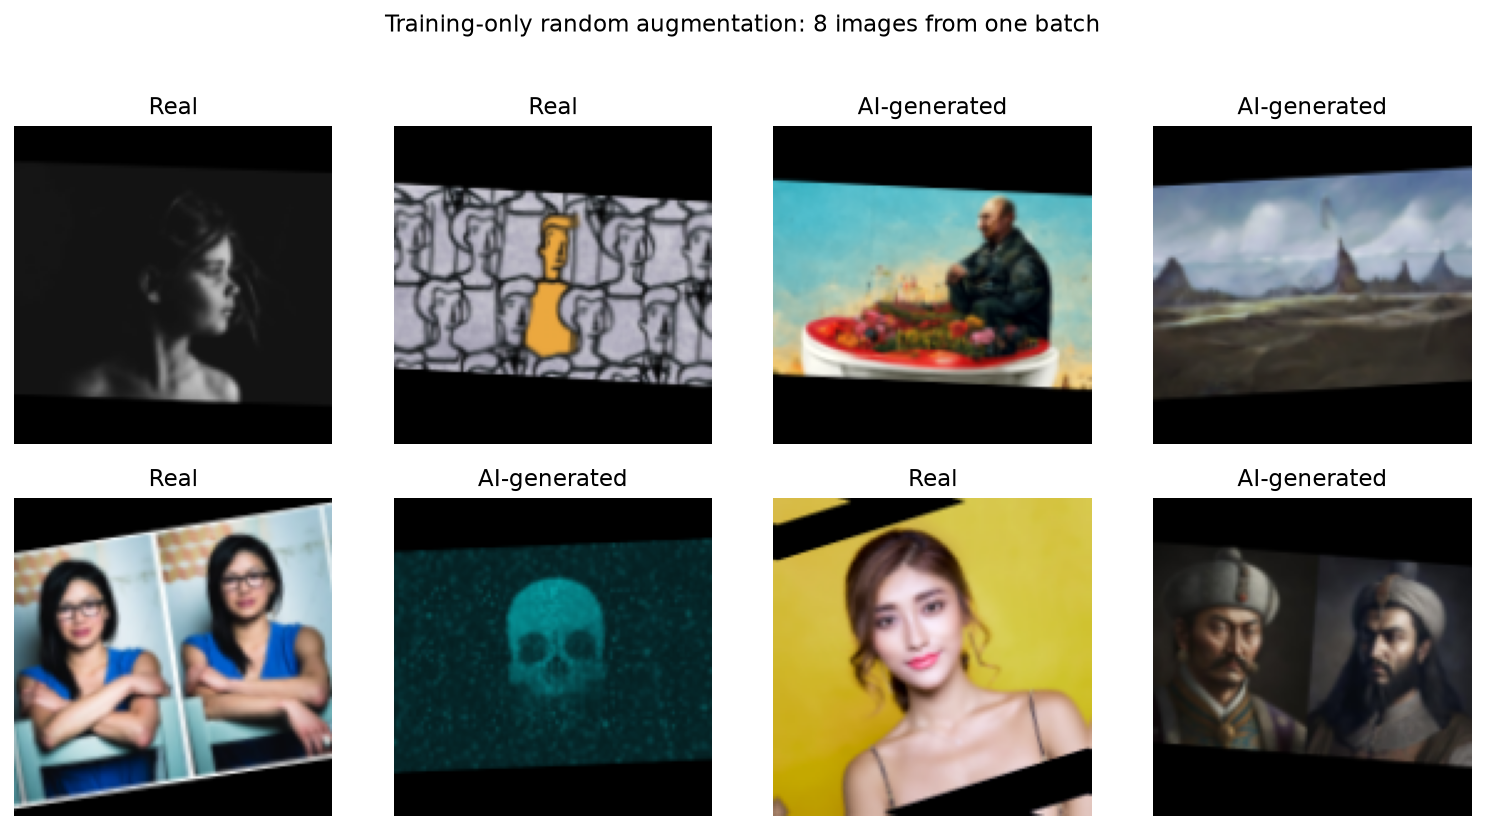

Batch shape: (16, 128, 128, 3) dtype: <dtype: 'float32'>
Positive class: AI-generated (1); negative class: Real (0).


In [9]:
import os
os.environ.setdefault("KERAS_HOME", str(Path.cwd() / "artifacts" / "keras_cache"))
import io
import random
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from PIL import ImageOps
from IPython.display import Image as NotebookImage

SEED = 42
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 16
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
# Limit parallel CPU work so the desktop remains usable.
try:
    tf.config.threading.set_intra_op_parallelism_threads(8)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    pass  # An already-running notebook kernel may have initialized TensorFlow.

usable = audit_df.loc[~audit_df["unreadable"]].copy()
if usable.groupby("sha256")["class"].nunique().gt(1).any():
    raise ValueError("Identical files have conflicting class labels; resolve before splitting.")
usable = usable.drop_duplicates("sha256").reset_index(drop=True)
usable["label"] = usable["class"].map({"Real": 0, "AI-generated": 1})
train_rows, heldout_rows = train_test_split(
    usable, test_size=0.30, random_state=SEED, stratify=usable["label"]
)
val_rows, test_rows = train_test_split(
    heldout_rows, test_size=0.50, random_state=SEED, stratify=heldout_rows["label"]
)
split_frames = {"train": train_rows, "validation": val_rows, "test": test_rows}
Path("splits").mkdir(exist_ok=True)
for name, frame in split_frames.items():
    frame[["path", "class", "label", "sha256"]].to_csv(f"splits/{name}.csv", index=False)
for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    assert set(split_frames[left]["sha256"]).isdisjoint(split_frames[right]["sha256"])
display(pd.crosstab(
    pd.concat([frame.assign(split=name) for name, frame in split_frames.items()])["split"],
    pd.concat([frame.assign(split=name) for name, frame in split_frames.items()])["class"],
))

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.05, fill_mode="reflect", seed=SEED + 1),
    layers.RandomZoom(0.10, fill_mode="reflect", seed=SEED + 2),
    layers.RandomContrast(0.10, seed=SEED + 3),
], name="training_augmentation")

def pillow_decode(path_bytes):
    path = path_bytes.decode("utf-8")
    with Image.open(path) as image:
        image.seek(0)
        return np.asarray(ImageOps.exif_transpose(image).convert("RGB"), dtype=np.uint8)

def decode_resize(path, label):
    image = tf.numpy_function(pillow_decode, [path], tf.uint8)
    image.set_shape([None, None, 3])
    image = tf.image.resize_with_pad(image, *IMAGE_SIZE, antialias=True)
    return image, tf.cast(label, tf.float32)

def make_dataset(split_name, training=False, augment=True):
    frame = pd.read_csv(f"splits/{split_name}.csv")
    paths = [str(dataset_root / path) for path in frame["path"]]
    ds = tf.data.Dataset.from_tensor_slices((paths, frame["label"].to_numpy()))
    options = tf.data.Options()
    options.experimental_deterministic = True
    options.threading.private_threadpool_size = 4
    ds = ds.with_options(options).map(decode_resize, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    if training and augment:
        ds = ds.map(lambda x, y: (tf.clip_by_value(augmentation(x, training=True), 0, 255), y),
                    num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset("train", training=True)
val_ds = make_dataset("validation")
test_ds = make_dataset("test")  # Kept untouched until the one-time evaluation in 2.5.

def show_figure(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=140, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(NotebookImage(data=buffer.getvalue()))

batch_images, batch_labels = next(iter(train_ds))
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for index, ax in enumerate(axes.flat):
    ax.imshow(batch_images[index].numpy().astype("uint8"))
    ax.set_title("AI-generated" if int(batch_labels[index]) else "Real")
    ax.axis("off")
fig.suptitle("Training-only random augmentation: 8 images from one batch")
fig.tight_layout(h_pad=3.0, rect=(0, 0, 1, 0.94))
show_figure(fig)
print("Batch shape:", batch_images.shape, "dtype:", batch_images.dtype)
print("Positive class: AI-generated (1); negative class: Real (0).")


**Figure 5. Eight examples from one augmented training batch (seed 42).**

The batch contains RGB images with a common 128 x 128 shape, while padding preserves their original proportions. Modest random transformations add training variation; validation and test batches receive none of these augmentations. Folder labels are used as supplied and may include artwork in the Real class.


## 2.2 Baseline CNN

I designed a small CNN with three convolution blocks (16, 32 and 64 filters). Convolutions learn local visual patterns, batch normalization stabilizes activations, ReLU adds nonlinearity, and max pooling reduces spatial size and computation; global average pooling replaces a large flattened vector to limit parameters. A 64-unit dense layer combines features, dropout (0.4) reduces co-adaptation, and one sigmoid unit returns the probability of the positive AI-generated class.

The model rescales [0,255] pixels to [0,1] internally. Binary cross-entropy matches the two-class sigmoid output; Adam with learning rate 0.001 is the starting optimizer. Accuracy, precision, recall and ROC-AUC track different aspects of performance; training uses class weights to compensate for unequal class counts. Precision/recall here use 0.5 temporarily; the final operating thresholds will be chosen from validation data in 2.5.


Model: "baseline_cnn"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rgb_image (InputLayer)          │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pixel_scaling (Rescaling)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 128, 128, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 128, 128, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 128, 128, 1

,layer,type,output_shape,parameters
0,rgb_image,InputLayer,"(None, 128, 128, 3)",0
1,pixel_scaling,Rescaling,"(None, 128, 128, 3)",0
2,conv_1,Conv2D,"(None, 128, 128, 16)",432
3,batch_norm_1,BatchNormalization,"(None, 128, 128, 16)",64
4,relu_1,Activation,"(None, 128, 128, 16)",0
5,pool_1,MaxPooling2D,"(None, 64, 64, 16)",0
6,conv_2,Conv2D,"(None, 64, 64, 32)",4608
7,batch_norm_2,BatchNormalization,"(None, 64, 64, 32)",128
8,relu_2,Activation,"(None, 64, 64, 32)",0
9,pool_2,MaxPooling2D,"(None, 32, 32, 32)",0


Total parameters: 28145


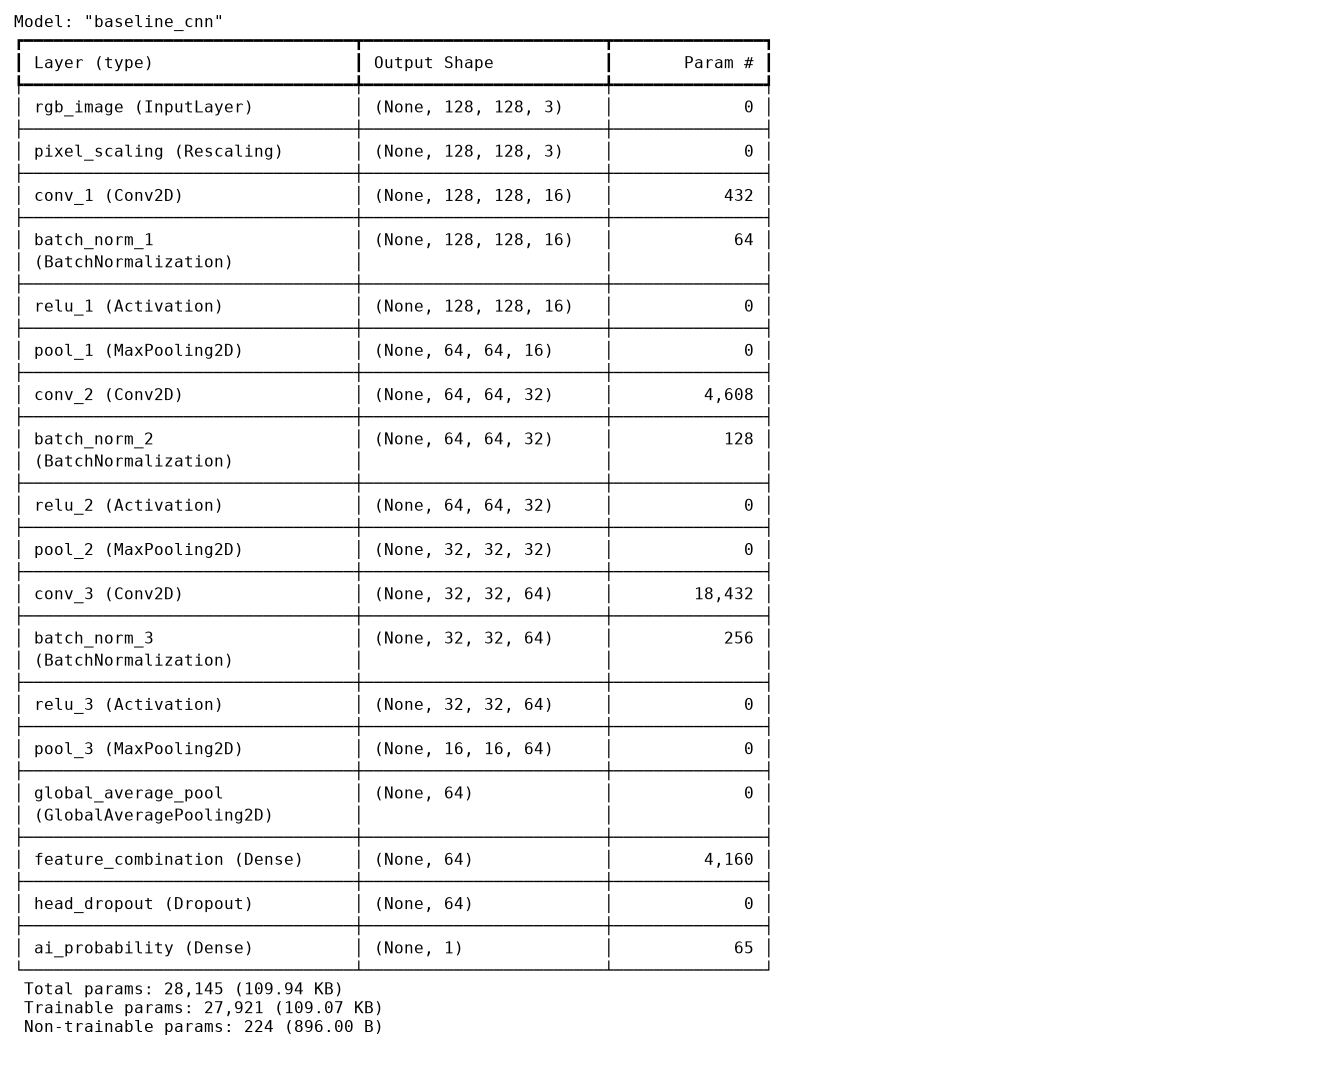

Class weights: {1: 0.9055851063829787, 0: 1.116393442622951}


D:\Mamoon\Code\MLOps-A2\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/20


D:\Mamoon\Code\MLOps-A2\.venv\Lib\site-packages\PIL\Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


43/43 - 6s - 147ms/step - accuracy: 0.5374 - auc: 0.5584 - loss: 0.7021 - precision: 0.5894 - recall: 0.5346 - val_accuracy: 0.4452 - val_auc: 0.5974 - val_loss: 0.7042 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/20
43/43 - 2s - 52ms/step - accuracy: 0.5830 - auc: 0.6262 - loss: 0.6706 - precision: 0.6211 - recall: 0.6277 - val_accuracy: 0.4589 - val_auc: 0.6402 - val_loss: 0.6970 - val_precision: 0.6667 - val_recall: 0.0494 - learning_rate: 0.0010
Epoch 3/20
43/43 - 2s - 51ms/step - accuracy: 0.6035 - auc: 0.6539 - loss: 0.6613 - precision: 0.6606 - recall: 0.5798 - val_accuracy: 0.4452 - val_auc: 0.6681 - val_loss: 0.7313 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 4/20
43/43 - 2s - 51ms/step - accuracy: 0.6256 - auc: 0.6877 - loss: 0.6350 - precision: 0.6631 - recall: 0.6543 - val_accuracy: 0.5000 - val_auc: 0.6705 - val_loss: 0.7014 - val_precision: 0.7857 - val_recall: 0.1358 - learning_rate: 0.0010
Ep

In [10]:
def compile_binary(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss="binary_crossentropy",
        metrics=[keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.AUC(name="auc"),
                 keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")],
    )

def build_baseline():
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name="rgb_image")
    x = layers.Rescaling(1 / 255.0, name="pixel_scaling")(inputs)
    for block, filters in enumerate([16, 32, 64], start=1):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"conv_{block}")(x)
        x = layers.BatchNormalization(name=f"batch_norm_{block}")(x)
        x = layers.Activation("relu", name=f"relu_{block}")(x)
        x = layers.MaxPooling2D(name=f"pool_{block}")(x)
    x = layers.GlobalAveragePooling2D(name="global_average_pool")(x)
    x = layers.Dense(64, activation="relu", name="feature_combination")(x)
    x = layers.Dropout(0.4, seed=SEED, name="head_dropout")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="ai_probability")(x)
    model = keras.Model(inputs, outputs, name="baseline_cnn")
    compile_binary(model, 1e-3)
    return model

baseline = build_baseline()
baseline.summary()
layer_table = pd.DataFrame([
    {"layer": layer.name, "type": type(layer).__name__,
     "output_shape": str(layer.output.shape), "parameters": layer.count_params()}
    for layer in baseline.layers
])
display(layer_table)
print("Total parameters:", baseline.count_params())

# An image of the actual summary output is included for report evidence.
summary_lines = []
baseline.summary(print_fn=lambda line, **kwargs: summary_lines.append(line))
fig, ax = plt.subplots(figsize=(12, 9))
ax.axis("off")
ax.text(0, 1, "\n".join(summary_lines), family="DejaVu Sans Mono", fontsize=8,
        va="top", transform=ax.transAxes)
show_figure(fig)

def training_callbacks(name, patience=4):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(str(ARTIFACTS / f"{name}.keras"), monitor="val_loss", save_best_only=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7),
    ]

training_labels = pd.read_csv("splits/train.csv")["label"]
class_weight = {int(label): len(training_labels) / (2 * count)
                for label, count in training_labels.value_counts().items()}
print("Class weights:", class_weight)
baseline_history = baseline.fit(train_ds, validation_data=val_ds, epochs=20,
                               callbacks=training_callbacks("baseline_best"),
                               class_weight=class_weight, verbose=2)
baseline = keras.models.load_model(ARTIFACTS / "baseline_best.keras")
pd.DataFrame(baseline_history.history).to_csv(ARTIFACTS / "baseline_history.csv", index=False)
print("Baseline best epoch:", int(np.argmin(baseline_history.history["val_loss"])) + 1)


**Figure 6. Keras baseline summary output; the table above records output shape and parameter count for every layer.**


## 2.3 Transfer learning

I use ImageNet-pretrained MobileNetV2 with `include_top=False`, width multiplier 0.35 and 128 x 128 RGB inputs to keep CPU training practical. Global average pooling, dropout and a sigmoid head replace the original classifier. The input rescaling `x / 127.5 - 1` is equivalent to MobileNetV2's required `preprocess_input`, which maps pixels to [-1,1]; using the baseline's [0,1] preprocessing would mismatch the pretrained weights.

Stage 1 freezes the entire backbone and trains only the new head with Adam at 0.001. Stage 2 starts from the best stage-1 checkpoint and unfreezes only the final inverted-residual block (`block_16_*`) and final `Conv_1` projection, using 0.00001 (100 times smaller). Batch-normalization layers remain frozen and the backbone is called with `training=False` so its moving statistics do not drift on this small dataset. The lists below show exactly which weighted layers are trainable in each stage.

Reference: [Keras MobileNetV2 preprocessing](https://keras.io/api/applications/mobilenet/).



      0/2019640 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step
  16384/2019640 ━━━━━━━━━━━━━━━━━━━━ 20s 10us/step
  32768/2019640 ━━━━━━━━━━━━━━━━━━━━ 15s 8us/step 
  49152/2019640 ━━━━━━━━━━━━━━━━━━━━ 15s 8us/step
  73728/2019640 ━━━━━━━━━━━━━━━━━━━━ 11s 6us/step
  81920/2019640 ━━━━━━━━━━━━━━━━━━━━ 14s 7us/step
 114688/2019640 ━━━━━━━━━━━━━━━━━━━━ 11s 6us/step
 147456/2019640 ━━━━━━━━━━━━━━━━━━━━ 9s 5us/step 
 180224/2019640 ━━━━━━━━━━━━━━━━━━━━ 8s 5us/step
 212992/2019640 ━━━━━━━━━━━━━━━━━━━━ 7s 4us/step
 253952/2019640 ━━━━━━━━━━━━━━━━━━━━ 6s 4us/step
 311296/2019640 ━━━━━━━━━━━━━━━━━━━━ 5s 3us/step
 376832/2019640 ━━━━━━━━━━━━━━━━━━━━ 4s 3us/step
 442368/2019640 ━━━━━━━━━━━━━━━━━━━━ 3s 3us/step
 516096/2019640 ━━━━━━━━━━━━━━━━━━━━ 3s 2us/step
 614400/2019640 ━━━━━━━━━━━━━━━━━━━━ 2s 2us/step
 737280/2019640 ━━━━━━━━━━━━━━━━━━━━ 2s 2us/step
 868352/2019640 ━━━━━━━━━━━━━━━━━━━━ 1s 2us/step
1032192/2019640 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
1212416/2019640 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
1474560/201

,layer,trainable_parameters
0,ai_probability,1281


D:\Mamoon\Code\MLOps-A2\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/12
43/43 - 5s - 109ms/step - accuracy: 0.5507 - auc: 0.5665 - loss: 0.7855 - precision: 0.6023 - recall: 0.5479 - val_accuracy: 0.6781 - val_auc: 0.7575 - val_loss: 0.6102 - val_precision: 0.7742 - val_recall: 0.5926 - learning_rate: 0.0010
Epoch 2/12
43/43 - 2s - 42ms/step - accuracy: 0.6505 - auc: 0.6982 - loss: 0.6587 - precision: 0.6875 - recall: 0.6729 - val_accuracy: 0.7192 - val_auc: 0.8047 - val_loss: 0.5897 - val_precision: 0.8704 - val_recall: 0.5802 - learning_rate: 0.0010
Epoch 3/12
43/43 - 2s - 42ms/step - accuracy: 0.6872 - auc: 0.7554 - loss: 0.6064 - precision: 0.7349 - recall: 0.6782 - val_accuracy: 0.7466 - val_auc: 0.8368 - val_loss: 0.5429 - val_precision: 0.8667 - val_recall: 0.6420 - learning_rate: 0.0010
Epoch 4/12
43/43 - 2s - 38ms/step - accuracy: 0.6975 - auc: 0.7734 - loss: 0.5806 - precision: 0.7361 - recall: 0.7048 - val_accuracy: 0.7260 - val_auc: 0.8419 - val_loss: 0.5634 - val_precision: 0.8596 - val_recall: 0.6049 - learning_rate: 0.0010
Epoch 5

,layer,trainable_parameters
0,block_16_expand,18816
1,block_16_depthwise,3024
2,block_16_project,37632
3,Conv_1,143360
4,ai_probability,1281


D:\Mamoon\Code\MLOps-A2\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/12
43/43 - 5s - 114ms/step - accuracy: 0.7915 - auc: 0.8721 - loss: 0.4548 - precision: 0.8112 - recall: 0.8112 - val_accuracy: 0.7397 - val_auc: 0.8587 - val_loss: 0.5059 - val_precision: 0.8413 - val_recall: 0.6543 - learning_rate: 1.0000e-05
Epoch 2/12
43/43 - 2s - 44ms/step - accuracy: 0.7885 - auc: 0.8691 - loss: 0.4525 - precision: 0.8277 - recall: 0.7793 - val_accuracy: 0.7603 - val_auc: 0.8593 - val_loss: 0.4999 - val_precision: 0.8485 - val_recall: 0.6914 - learning_rate: 1.0000e-05
Epoch 3/12
43/43 - 2s - 43ms/step - accuracy: 0.8003 - auc: 0.8707 - loss: 0.4523 - precision: 0.8371 - recall: 0.7926 - val_accuracy: 0.7603 - val_auc: 0.8594 - val_loss: 0.4943 - val_precision: 0.8485 - val_recall: 0.6914 - learning_rate: 1.0000e-05
Epoch 4/12
43/43 - 2s - 44ms/step - accuracy: 0.7724 - auc: 0.8560 - loss: 0.4710 - precision: 0.8095 - recall: 0.7686 - val_accuracy: 0.7603 - val_auc: 0.8601 - val_loss: 0.4860 - val_precision: 0.8485 - val_recall: 0.6914 - learning_rate: 1.

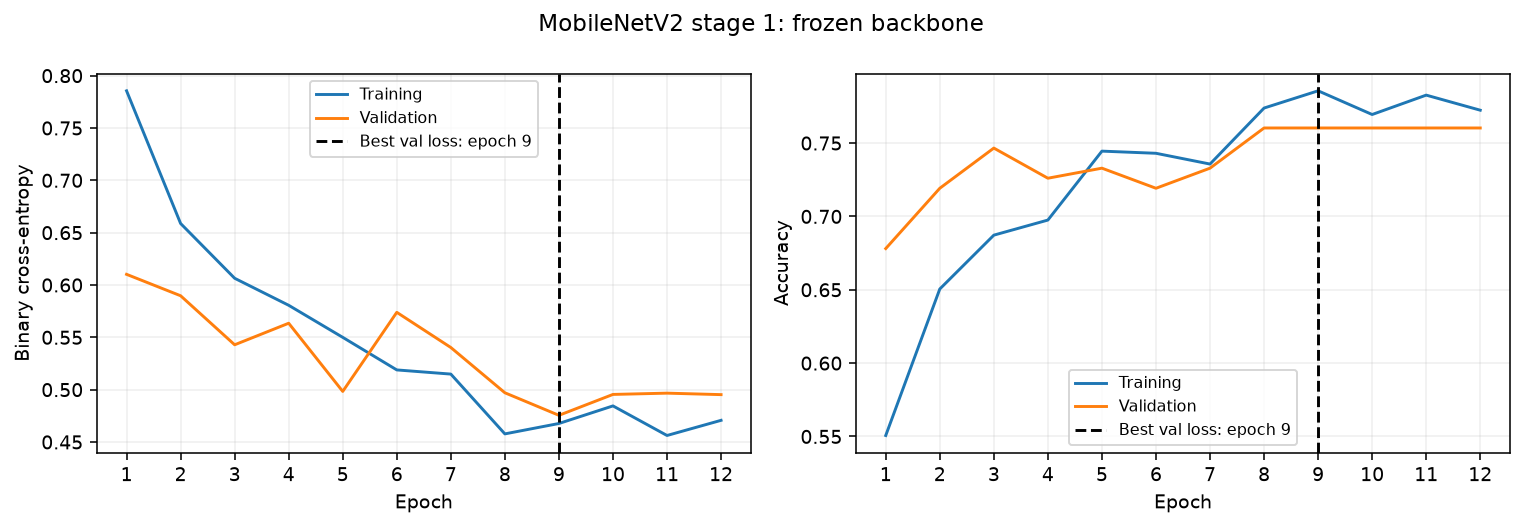

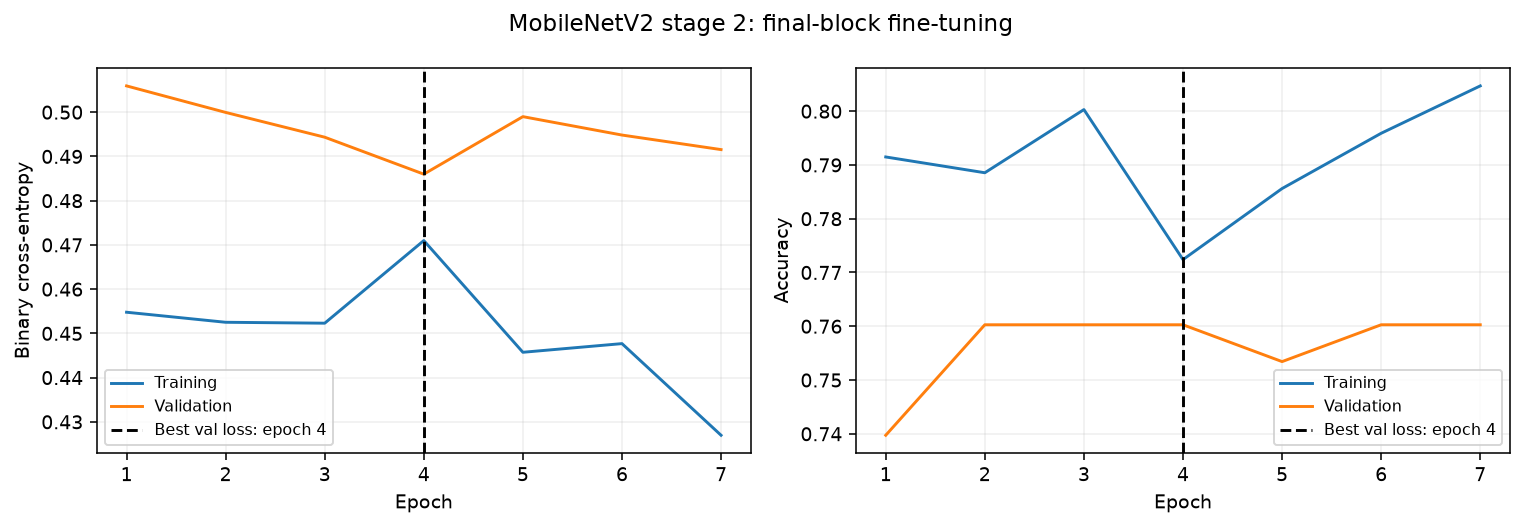

Stage 1 best epoch: 9
Stage 2 best epoch: 4


In [11]:
keras.utils.set_random_seed(SEED)
backbone = keras.applications.MobileNetV2(
    include_top=False, weights="imagenet", alpha=0.35, input_shape=(*IMAGE_SIZE, 3)
)
backbone.trainable = False
inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name="rgb_image")
x = layers.Rescaling(1 / 127.5, offset=-1, name="mobilenet_preprocessing")(inputs)
x = backbone(x, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pool")(x)
x = layers.Dropout(0.4, seed=SEED, name="head_dropout")(x)
outputs = layers.Dense(1, activation="sigmoid", name="ai_probability")(x)
transfer = keras.Model(inputs, outputs, name="mobilenet_transfer")
compile_binary(transfer, 1e-3)

def trainable_layer_table(model):
    rows = []
    for layer in model.layers:
        children = layer.layers if isinstance(layer, keras.Model) else [layer]
        for child in children:
            if child.trainable_weights:
                rows.append({"layer": child.name,
                             "trainable_parameters": int(sum(np.prod(w.shape) for w in child.trainable_weights))})
    return pd.DataFrame(rows)

print("Stage 1 trainable weighted layers:")
display(trainable_layer_table(transfer))
np.testing.assert_allclose(
    keras.applications.mobilenet_v2.preprocess_input(batch_images.numpy().copy()),
    batch_images.numpy() / 127.5 - 1, atol=1e-6,
)
frozen_history = transfer.fit(train_ds, validation_data=val_ds, epochs=12,
                              callbacks=training_callbacks("transfer_frozen", patience=3),
                              class_weight=class_weight, verbose=2)
transfer = keras.models.load_model(ARTIFACTS / "transfer_frozen.keras")
backbone = next(layer for layer in transfer.layers if isinstance(layer, keras.Model))
backbone.trainable = True
for layer in backbone.layers:
    layer.trainable = (layer.name.startswith("block_16_") or layer.name == "Conv_1") and not isinstance(layer, layers.BatchNormalization)
compile_binary(transfer, 1e-5)
print("Stage 2 trainable weighted layers:")
display(trainable_layer_table(transfer))
fine_history = transfer.fit(train_ds, validation_data=val_ds, epochs=12,
                           callbacks=training_callbacks("transfer_finetuned", patience=3),
                           class_weight=class_weight, verbose=2)
pd.DataFrame(frozen_history.history).to_csv(ARTIFACTS / "transfer_frozen_history.csv", index=False)
pd.DataFrame(fine_history.history).to_csv(ARTIFACTS / "transfer_finetuned_history.csv", index=False)

def plot_training(history, title):
    values = history.history if hasattr(history, "history") else history
    epochs = np.arange(1, len(values["loss"]) + 1)
    best_epoch = int(np.argmin(values["val_loss"])) + 1
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, metric, ylabel in zip(axes, ["loss", "accuracy"], ["Binary cross-entropy", "Accuracy"]):
        ax.plot(epochs, values[metric], label="Training")
        ax.plot(epochs, values[f"val_{metric}"], label="Validation")
        ax.axvline(best_epoch, color="black", linestyle="--", label=f"Best val loss: epoch {best_epoch}")
        ax.set(xlabel="Epoch", ylabel=ylabel)
        ax.set_xticks(epochs)
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    show_figure(fig)

plot_training(frozen_history, "MobileNetV2 stage 1: frozen backbone")
plot_training(fine_history, "MobileNetV2 stage 2: final-block fine-tuning")
print("Stage 1 best epoch:", int(np.argmin(frozen_history.history["val_loss"])) + 1)
print("Stage 2 best epoch:", int(np.argmin(fine_history.history["val_loss"])) + 1)


**Figures 7 and 8. Loss and accuracy curves for frozen-head training and final-block fine-tuning, with each stage's best validation-loss epoch marked.**


## 2.4 Training discipline

I fix Python, NumPy and TensorFlow seeds through `keras.utils.set_random_seed(42)` and enable deterministic TensorFlow operations. Every training stage uses early stopping on validation loss, a full-model checkpoint saved only when validation loss improves, and ReduceLROnPlateau (factor 0.5, patience 2); checkpoint selection never uses test scores. Training augmentation makes training loss/accuracy different from deterministic validation metrics, and class-weighted training loss is not directly identical to unweighted validation loss.

The table records the actual completed epochs and the best validation-loss epoch for each stage; dashed markers identify these epochs in all training plots. I compare frozen and fine-tuned checkpoint validation losses before choosing the transfer candidate, so an unsuccessful fine-tuning stage cannot automatically replace a better frozen model. The selected transfer model is copied to a stable local artifact for evaluation.


,stage,epochs_completed,best_epoch,best_validation_loss
0,Baseline CNN,20,20,0.549250
1,MobileNet frozen,12,9,0.475475
2,MobileNet fine-tuned,7,4,0.485992


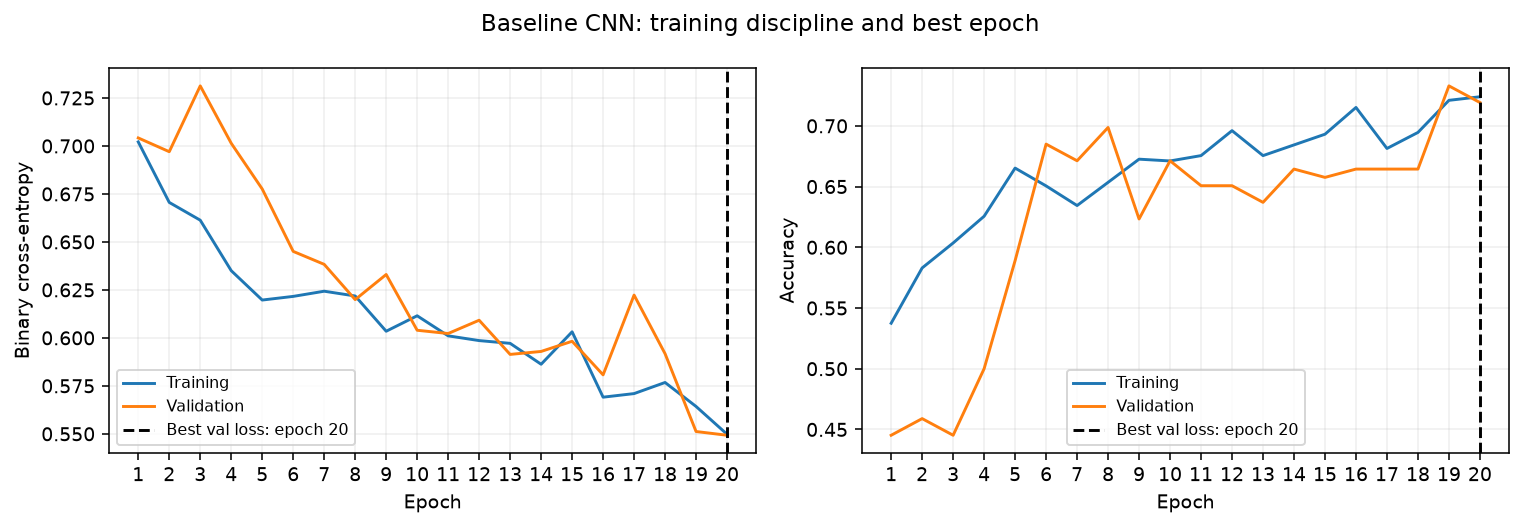

Transfer candidate chosen from validation loss: frozen


In [12]:
histories = {"Baseline CNN": baseline_history, "MobileNet frozen": frozen_history,
             "MobileNet fine-tuned": fine_history}
best_epochs = pd.DataFrame([
    {"stage": name, "epochs_completed": len(history.history["loss"]),
     "best_epoch": int(np.argmin(history.history["val_loss"])) + 1,
     "best_validation_loss": float(min(history.history["val_loss"]))}
    for name, history in histories.items()
])
display(best_epochs)
plot_training(baseline_history, "Baseline CNN: training discipline and best epoch")
frozen_loss = min(frozen_history.history["val_loss"])
fine_loss = min(fine_history.history["val_loss"])
selected_transfer_stage = "fine-tuned" if fine_loss < frozen_loss else "frozen"
selected_transfer_path = ARTIFACTS / ("transfer_finetuned.keras" if fine_loss < frozen_loss else "transfer_frozen.keras")
transfer = keras.models.load_model(selected_transfer_path)
transfer.save(ARTIFACTS / "transfer_selected.keras")
print("Transfer candidate chosen from validation loss:", selected_transfer_stage)
best_epochs.to_json(ARTIFACTS / "best_epochs.json", orient="records", indent=2)


**Figure 9. Baseline training/validation loss and accuracy; the marked epoch minimizes validation loss.**

The best validation-loss epochs were 20 for the baseline, 9 for frozen MobileNetV2 and 4 for fine-tuning. Frozen MobileNetV2 was retained because its best validation loss (0.4755) was lower than fine-tuning (0.4860).


## 2.5 One-time test evaluation

AI-generated is the positive class (1). For this product I treat falsely labelling a real image as fake as the more costly error, because it can undermine trust in authentic content; I assign false positives twice the cost of false negatives as an explicit product assumption. For each model I select the threshold that minimizes `(2 * false positives + false negatives) / validation_count`, breaking ties by higher positive-class F1 and then proximity to 0.5, using validation predictions only.

The final candidate is selected by validation cost (then validation loss), and both thresholds and the candidate name are frozen before any test prediction. Each fixed model predicts the test split exactly once; accuracy, precision, recall, F1, ROC-AUC, confusion matrices and ROC curves are all computed from those cached probabilities. Thresholds therefore do not use the test labels, ROC-AUC uses continuous probabilities, and no tuning or checkpoint selection is allowed to consume these test metrics.


,threshold,validation_cost,validation_f1,false_positives,false_negatives,validation_loss
model,,,,,,
Baseline CNN,0.663509,0.410959,0.569106,7,46,0.549250
MobileNetV2,0.676879,0.294521,0.716418,5,33,0.475475


Candidate selected before test prediction: MobileNetV2


,threshold,accuracy,precision_AI,recall_AI,F1_AI,ROC_AUC
model,,,,,,
Baseline CNN,0.6635,0.6327,0.8140,0.4321,0.5645,0.7406
MobileNetV2,0.6769,0.6871,0.8889,0.4938,0.6349,0.7761


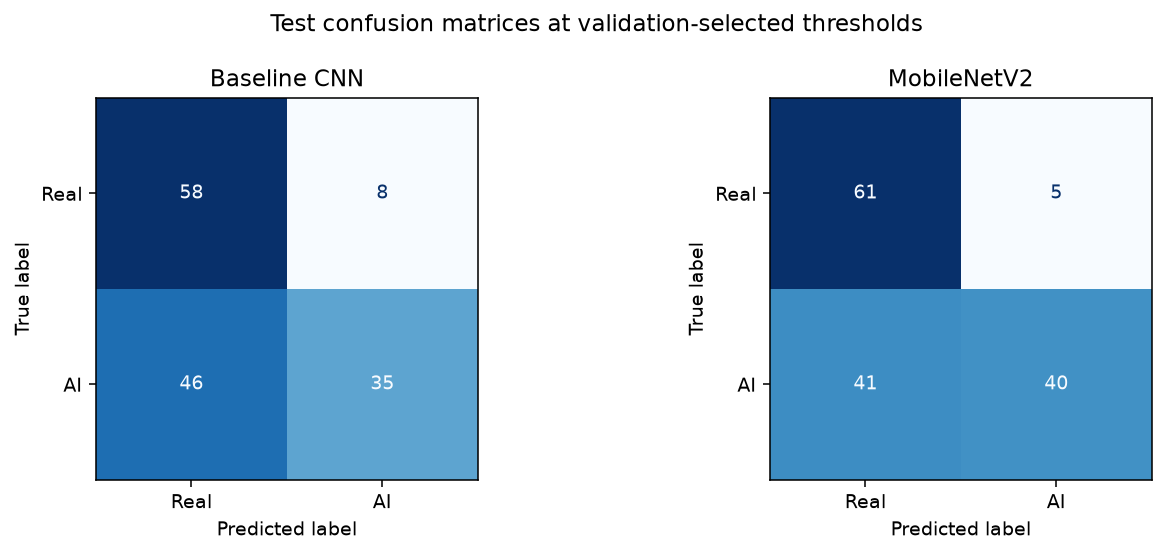

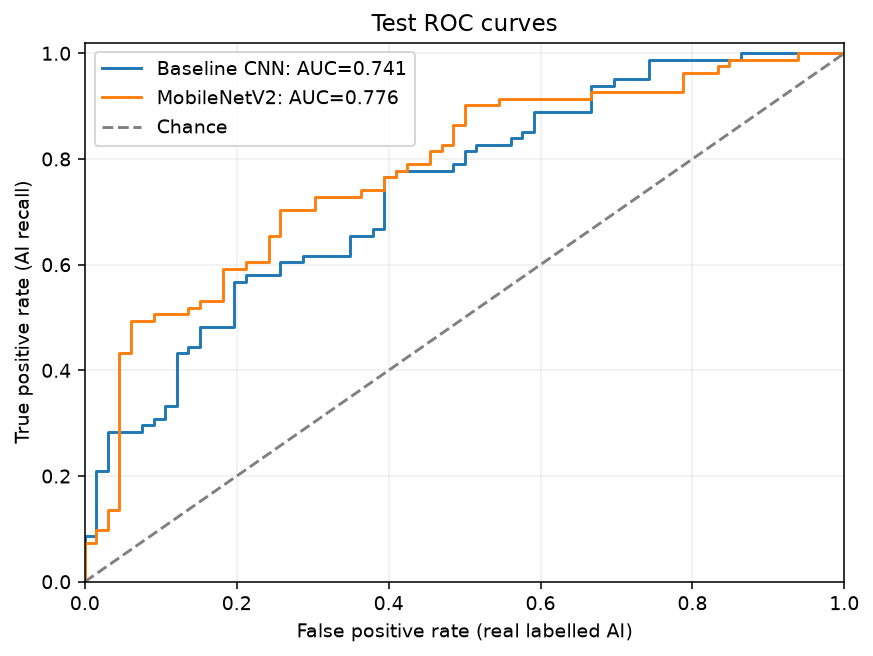

In [13]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, ConfusionMatrixDisplay)

validation_labels = pd.read_csv("splits/validation.csv")["label"].to_numpy()
models_to_compare = {"Baseline CNN": baseline, "MobileNetV2": transfer}

def choose_threshold(labels, probabilities):
    probabilities = np.asarray(probabilities, dtype=float)
    candidates = np.unique(np.r_[0.0, 0.5, 1.0, probabilities,
                                 np.nextafter(probabilities.astype(float), np.inf)])
    rows = []
    for threshold in candidates:
        predicted = probabilities >= threshold
        tn, fp, fn, tp = confusion_matrix(labels, predicted, labels=[0, 1]).ravel()
        rows.append({"threshold": float(threshold), "validation_cost": (2 * fp + fn) / len(labels),
                     "validation_f1": f1_score(labels, predicted, zero_division=0),
                     "distance_from_half": abs(threshold - 0.5), "false_positives": int(fp),
                     "false_negatives": int(fn)})
    return sorted(rows, key=lambda row: (row["validation_cost"], -row["validation_f1"], row["distance_from_half"]))[0]

validation_choices = []
for name, model in models_to_compare.items():
    val_prob = model.predict(val_ds, verbose=0).ravel().astype(float)
    choice = choose_threshold(validation_labels, val_prob)
    clipped = np.clip(val_prob, 1e-7, 1 - 1e-7)
    choice["validation_loss"] = float(-np.mean(validation_labels * np.log(clipped) + (1 - validation_labels) * np.log(1 - clipped)))
    choice["model"] = name
    validation_choices.append(choice)
threshold_table = pd.DataFrame(validation_choices).set_index("model")
display(threshold_table.drop(columns="distance_from_half"))
selected_model_name = threshold_table.sort_values(["validation_cost", "validation_loss"]).index[0]
print("Candidate selected before test prediction:", selected_model_name)
(ARTIFACTS / "evaluation_choices.json").write_text(json.dumps({
    "selected_model": selected_model_name, "positive_class": "AI-generated",
    "false_positive_cost": 2, "false_negative_cost": 1,
    "choices": validation_choices,
}, indent=2), encoding="utf-8")

prediction_path = ARTIFACTS / "test_predictions.npz"
if prediction_path.exists():
    raise RuntimeError("Test predictions already exist. Reuse the saved outputs; do not evaluate test again.")
test_frame = pd.read_csv("splits/test.csv")
y_test = test_frame["label"].to_numpy()
test_probabilities = {name: model.predict(test_ds, verbose=0).ravel().astype(float)
                      for name, model in models_to_compare.items()}
np.savez(prediction_path, y_test=y_test, baseline=test_probabilities["Baseline CNN"],
         mobilenet=test_probabilities["MobileNetV2"], paths=test_frame["path"].to_numpy(dtype=str))
metric_rows = []
for name, probabilities in test_probabilities.items():
    threshold = float(threshold_table.loc[name, "threshold"])
    predicted = (probabilities >= threshold).astype(int)
    metric_rows.append({"model": name, "threshold": threshold,
        "accuracy": accuracy_score(y_test, predicted),
        "precision_AI": precision_score(y_test, predicted, zero_division=0),
        "recall_AI": recall_score(y_test, predicted, zero_division=0),
        "F1_AI": f1_score(y_test, predicted, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, probabilities)})
metric_table = pd.DataFrame(metric_rows).set_index("model")
display(metric_table.round(4))
metric_table.to_csv(ARTIFACTS / "test_metrics.csv")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, probabilities) in zip(axes, test_probabilities.items()):
    predicted = probabilities >= threshold_table.loc[name, "threshold"]
    ConfusionMatrixDisplay.from_predictions(y_test, predicted, labels=[0, 1],
        display_labels=["Real", "AI"], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
fig.suptitle("Test confusion matrices at validation-selected thresholds")
fig.tight_layout()
show_figure(fig)
fig, ax = plt.subplots(figsize=(7, 5))
for name, probabilities in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    ax.plot(fpr, tpr, label=f"{name}: AUC={roc_auc_score(y_test, probabilities):.3f}")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Chance")
ax.set(xlabel="False positive rate (real labelled AI)", ylabel="True positive rate (AI recall)",
       title="Test ROC curves", xlim=(0, 1), ylim=(0, 1.02))
ax.legend()
ax.grid(alpha=0.2)
show_figure(fig)


**Figures 10 and 11. Confusion matrices at fixed validation-selected thresholds and ROC curves computed from the same one-time test predictions.**

On 147 held-out images, MobileNetV2 achieved 68.71% accuracy and ROC-AUC 0.7761, compared with 63.27% and 0.7406 for the baseline. Its conservative threshold reduced real-to-AI errors to 5 of 66 real images but missed 41 of 81 AI images, so the model remains unsuitable for confident authenticity claims.


## 2.6 Error analysis

I inspect ten distinct misclassified baseline test images at the threshold selected in 2.5, starting with the most confident errors. This analysis reuses the saved test probabilities instead of calling the model again; it diagnoses failures without changing the already evaluated model or threshold. Each explanation is a visual hypothesis, not a verified cause or a change to the dataset's folder label.


Total baseline test errors: 54


,path,true_label,probability_AI,predicted_label,confidence
0,RealArt/RealArt/forest-landscape_71767-127.jpg,0,0.852758,1,0.852758
1,RealArt/RealArt/pexels-photo-2422290.jpeg,0,0.793240,1,0.793240
2,AiArtData/AiArtData/aiart.png,1,0.220095,0,0.779905
3,RealArt/RealArt/sunset-trees-abstract-painting...,0,0.748348,1,0.748348
4,RealArt/RealArt/index-celebs-who-ran-for-offic...,0,0.743760,1,0.743760
5,RealArt/RealArt/beautiful-scenery-in-autumn-se...,0,0.742631,1,0.742631
6,RealArt/RealArt/r19032hr19032c_composite_rd.jpg,0,0.720187,1,0.720187
7,RealArt/RealArt/Monroe_Exotic_Animals_Texas4.jpg,0,0.716072,1,0.716072
8,AiArtData/AiArtData/ai-cartoon-portraits-01.jpg,1,0.288785,0,0.711215
9,AiArtData/AiArtData/240201-airec-main-ksp-5625...,1,0.290244,0,0.709756


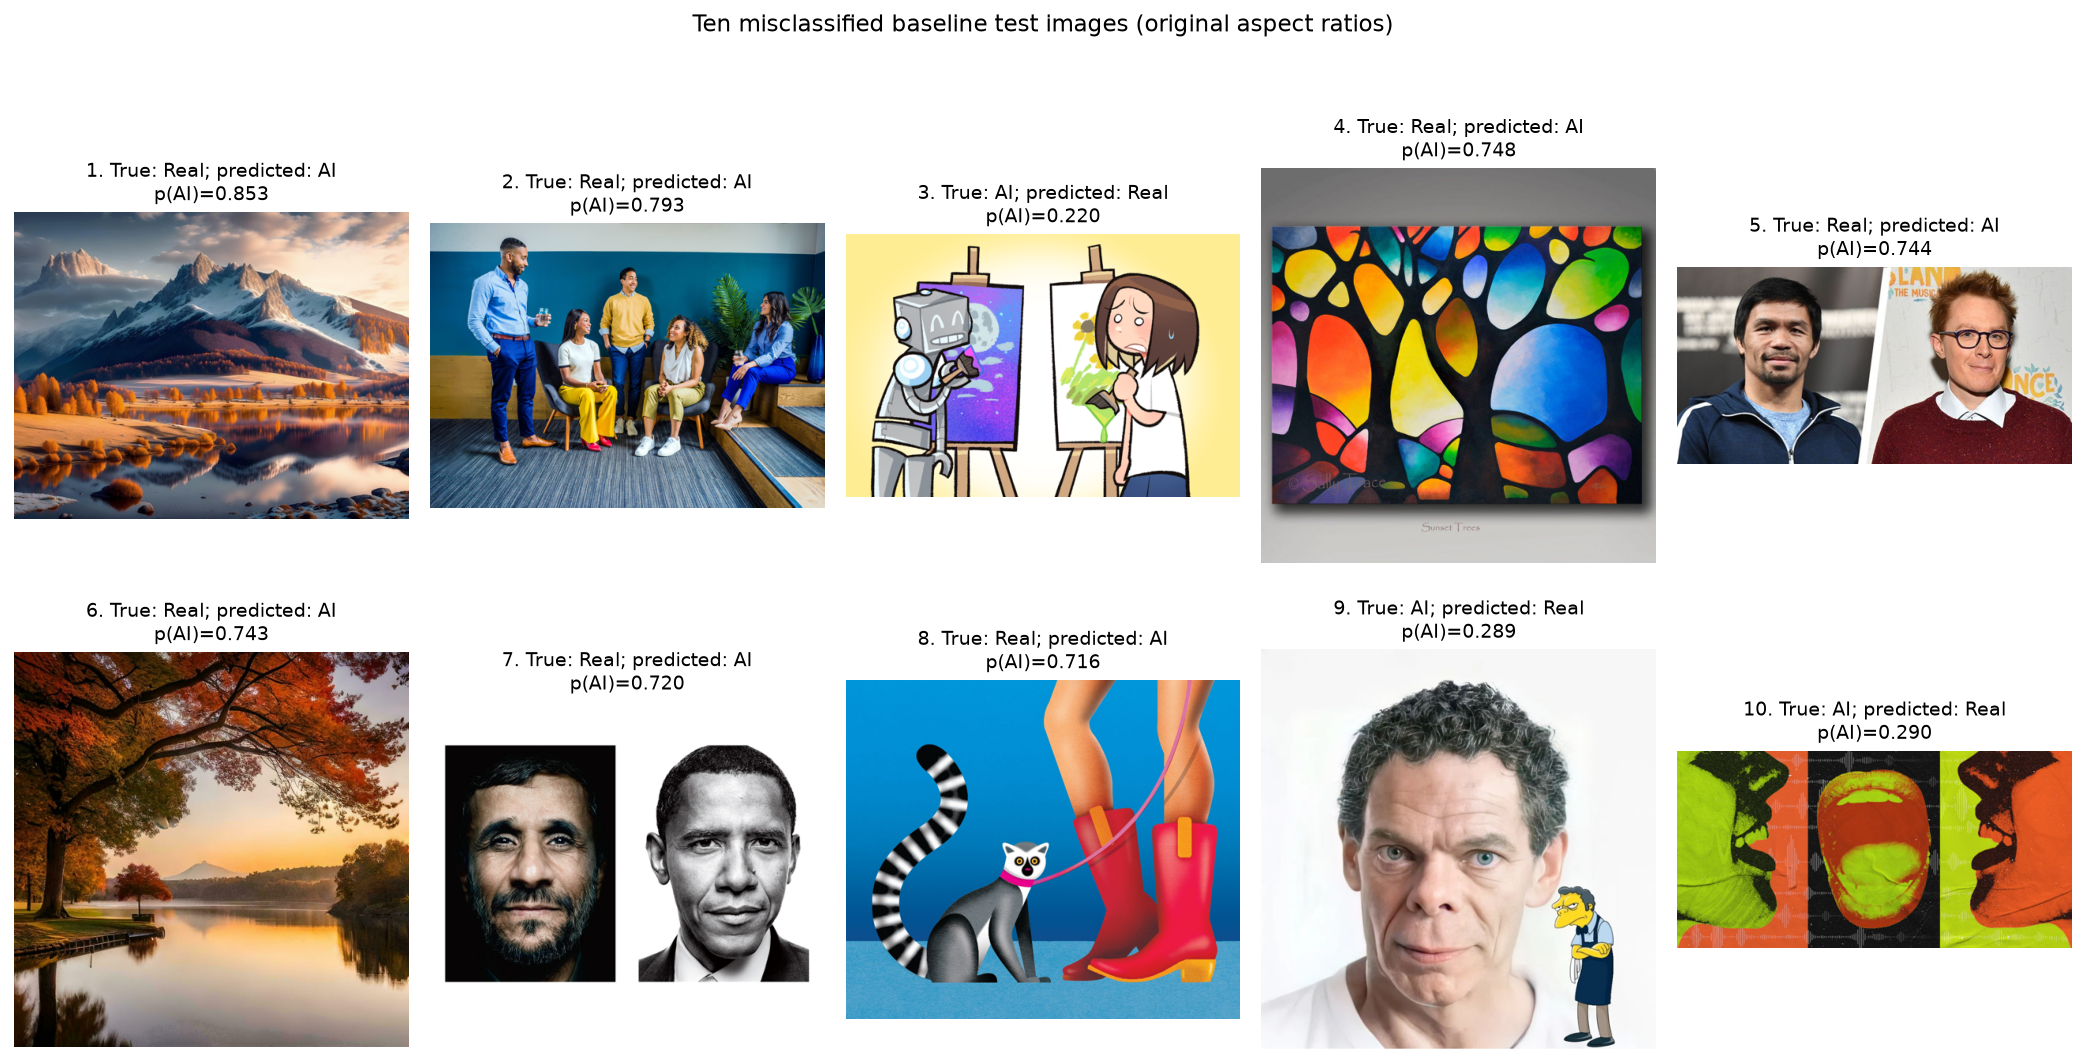

In [14]:
cached = np.load(ARTIFACTS / "test_predictions.npz")
baseline_threshold = float(threshold_table.loc["Baseline CNN", "threshold"])
error_rows = pd.DataFrame({"path": cached["paths"], "true_label": cached["y_test"],
                           "probability_AI": cached["baseline"]})
error_rows["predicted_label"] = (error_rows["probability_AI"] >= baseline_threshold).astype(int)
error_rows["confidence"] = np.where(error_rows["predicted_label"] == 1,
                                    error_rows["probability_AI"], 1 - error_rows["probability_AI"])
error_rows = error_rows.loc[error_rows["true_label"] != error_rows["predicted_label"]].sort_values("confidence", ascending=False)
print("Total baseline test errors:", len(error_rows))
if len(error_rows) < 10:
    raise ValueError("Fewer than ten actual baseline errors; do not invent misclassifications.")
error_examples = error_rows.head(10).reset_index(drop=True)
display(error_examples)
fig, axes = plt.subplots(2, 5, figsize=(15, 8))
for index, ax in enumerate(axes.flat):
    row = error_examples.iloc[index]
    with Image.open(dataset_root / row["path"]) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        image.thumbnail((500, 500))
        ax.imshow(image)
    actual = "AI" if row["true_label"] else "Real"
    predicted = "AI" if row["predicted_label"] else "Real"
    ax.set_title(f"{index+1}. True: {actual}; predicted: {predicted}\np(AI)={row['probability_AI']:.3f}", fontsize=10)
    ax.axis("off")
fig.suptitle("Ten misclassified baseline test images (original aspect ratios)")
fig.tight_layout(h_pad=3.0, rect=(0, 0, 1, 0.94))
show_figure(fig)
error_examples.to_csv(ARTIFACTS / "error_examples.csv", index=False)


**Figure 12. Ten distinct baseline errors, labelled with folder ground truth, predicted class and AI probability.**

1. The mountain scene has highly saturated colours and smooth, dramatic lighting, which may resemble synthetic imagery despite its Real folder label.
2. The office photograph has polished stock-photo lighting and a uniform blue background, which may have triggered appearance cues learned from AI images.
3. The AI-labelled cartoon uses simple outlines and flat colours; the baseline may associate this illustration style with artwork found in the Real class.
4. The Real-labelled abstract painting contains vivid, smooth colour regions, making artistic style a possible shortcut for the false AI prediction.
5. The Real-labelled side-by-side portraits contain composite boundaries and different backgrounds, which may resemble an edited or generated image.
6. The autumn landscape has intense colour and a very smooth reflection; its filename also contains ai-generative despite its Real folder label, so possible label noise needs manual source verification.
7. The Real-labelled composite mixes colour and monochrome portraits, which may create texture and contrast changes the baseline mistakes for generation artifacts.
8. The Real-labelled cartoon has smooth gradients, simplified anatomy and saturated colours, again suggesting that the baseline may confuse illustration style with AI origin.
9. The AI-labelled portrait combines a photographic face and a small cartoon; realistic facial texture may dominate the features used by the baseline.
10. The AI-labelled pop-art collage uses flat colours and repeated forms that could also appear in human-made art, making visual style an unreliable source cue.

These are hypotheses based on appearance, not proven explanations; the supplied labels were kept unchanged.


## 2.7 Keras Tuner toy lab and VisionGuard search

The toy lab uses a fixed stratified subset of Fashion-MNIST's training partition (6,000 train and 1,500 validation examples); the built-in test partition is unused. RandomSearch compares four tiny dense networks while varying learning rate and hidden units, then reports the best settings and each trial's validation accuracy.

The VisionGuard search runs at least eight RandomSearch trials varying Adam learning rate, dropout and the number of final convolution/depthwise layers unfrozen. Every trial starts from the same best frozen-head checkpoint, keeps batch normalization frozen, uses the same train/validation lists, and receives at most five epochs with early stopping and learning-rate reduction. The toy subset and short search budget are explicitly limited CPU experiments, not a claim of exhaustive optimization.

These searches use validation data only. They do not replace or retest the two fixed models already evaluated in 2.5: after looking at test results, a new candidate would need a fresh independent test set for an unbiased final assessment. Trying many settings can overfit the validation set by selecting a configuration that benefits from random validation noise; a larger independent validation set, nested validation or a fresh final holdout would reduce that risk.

Reference: [Keras Tuner RandomSearch](https://keras.io/keras_tuner/getting_started/).


In [15]:
import keras_tuner as kt
keras.utils.set_random_seed(SEED)
(fashion_images, fashion_labels), _ = keras.datasets.fashion_mnist.load_data()
toy_indices, _ = train_test_split(np.arange(len(fashion_labels)), train_size=7500,
                                  random_state=SEED, stratify=fashion_labels)
toy_train_indices, toy_val_indices = train_test_split(toy_indices, test_size=1500,
    random_state=SEED, stratify=fashion_labels[toy_indices])
toy_x_train = fashion_images[toy_train_indices].astype("float32") / 255
toy_x_val = fashion_images[toy_val_indices].astype("float32") / 255

def build_toy(hp):
    model = keras.Sequential([
        keras.Input((28, 28)), layers.Flatten(),
        layers.Dense(hp.Choice("units", [32, 64, 128]), activation="relu"),
        layers.Dense(10, activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(hp.Choice("learning_rate", [1e-4, 1e-3, 1e-2])),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

toy_tuner = kt.RandomSearch(build_toy, objective="val_accuracy", max_trials=4, seed=SEED,
    directory=str(ARTIFACTS / "tuning"), project_name="fashion_mnist", overwrite=False)
toy_tuner.search(toy_x_train, fashion_labels[toy_train_indices],
    validation_data=(toy_x_val, fashion_labels[toy_val_indices]), epochs=4, batch_size=64,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)], verbose=2)

def tuner_table(tuner):
    return pd.DataFrame([{"trial": trial.trial_id, **trial.hyperparameters.values,
                          "validation_score": trial.score, "status": trial.status}
                         for trial in tuner.oracle.trials.values()]).sort_values("validation_score", ascending=False)

toy_results = tuner_table(toy_tuner)
display(toy_results)
print("Best toy settings:", toy_tuner.get_best_hyperparameters(1)[0].values)

def build_visionguard_trial(hp):
    # Warm-start every configuration from identical trained head/backbone weights.
    model = keras.models.load_model(ARTIFACTS / "transfer_frozen.keras", compile=False)
    model.get_layer("head_dropout").rate = hp.Choice("dropout", [0.2, 0.4, 0.6])
    base = next(layer for layer in model.layers if isinstance(layer, keras.Model))
    count = hp.Choice("unfrozen_layers", [0, 2, 4])
    base.trainable = True
    for layer in base.layers:
        layer.trainable = False
    eligible = [layer for layer in base.layers if isinstance(layer, (layers.Conv2D, layers.DepthwiseConv2D))]
    if count:
        for layer in eligible[-count:]: layer.trainable = True
    compile_binary(model, hp.Choice("learning_rate", [1e-5, 1e-4, 1e-3]))
    return model

vision_tuner = kt.RandomSearch(build_visionguard_trial, objective=kt.Objective("val_auc", direction="max"),
    max_trials=8, seed=SEED, directory=str(ARTIFACTS / "tuning"), project_name="visionguard", overwrite=False)
vision_tuner.search(train_ds, validation_data=val_ds, epochs=5, class_weight=class_weight,
    callbacks=training_callbacks("tuner_latest_trial", patience=2), verbose=2)
vision_results = tuner_table(vision_tuner)
assert len(vision_results.loc[vision_results["status"] == "COMPLETED"]) >= 8
display(vision_results)
print("Best VisionGuard settings (validation ROC-AUC):", vision_tuner.get_best_hyperparameters(1)[0].values)
vision_tuner.get_best_models(1)[0].save(ARTIFACTS / "tuned_validation_candidate.keras")

# Observed score spread is descriptive: eight random trials do not isolate causal effects.
influence_rows = []
for parameter in ["learning_rate", "dropout", "unfrozen_layers"]:
    grouped = vision_results.groupby(parameter)["validation_score"].agg(["mean", "count"])
    print(f"Validation ROC-AUC grouped by {parameter}:")
    display(grouped)
    influence_rows.append({"parameter": parameter, "range_of_group_mean_AUC": grouped["mean"].max() - grouped["mean"].min()})
influence_table = pd.DataFrame(influence_rows).sort_values("range_of_group_mean_AUC", ascending=False)
display(influence_table)
print("Largest observed score spread:", influence_table.iloc[0]["parameter"])
print("This is an association across a small, confounded random search, not causal importance.")
toy_results.to_csv(ARTIFACTS / "toy_tuner_results.csv", index=False)
vision_results.to_csv(ARTIFACTS / "visionguard_tuner_results.csv", index=False)



Search: Running Trial #1

Value             |Best Value So Far |Hyperparameter
64                |64                |units
0.0001            |0.0001            |learning_rate

Epoch 1/4
94/94 - 1s - 7ms/step - accuracy: 0.4387 - loss: 1.8565 - val_accuracy: 0.6247 - val_loss: 1.4653
Epoch 2/4
94/94 - 0s - 2ms/step - accuracy: 0.6522 - loss: 1.2231 - val_accuracy: 0.6840 - val_loss: 1.0712
Epoch 3/4
94/94 - 0s - 2ms/step - accuracy: 0.7005 - loss: 0.9576 - val_accuracy: 0.7107 - val_loss: 0.9108
Epoch 4/4
94/94 - 0s - 2ms/step - accuracy: 0.7313 - loss: 0.8362 - val_accuracy: 0.7367 - val_loss: 0.8237
Trial 1 Complete [00h 00m 02s]
val_accuracy: 0.7366666793823242

Best val_accuracy So Far: 0.7366666793823242
Total elapsed time: 00h 00m 02s

Search: Running Trial #2

Value             |Best Value So Far |Hyperparameter
128               |64                |units
0.001             |0.0001            |learning_rate

Epoch 1/4
94/94 - 1s - 7ms/step - accuracy: 0.6960 - loss: 0.8881 - val_

,trial,units,learning_rate,validation_score,status
1,1,128,0.0010,0.829333,COMPLETED
3,3,32,0.0010,0.819333,COMPLETED
2,2,128,0.0001,0.772667,COMPLETED
0,0,64,0.0001,0.736667,COMPLETED


Best toy settings: {'units': 128, 'learning_rate': 0.001}

Search: Running Trial #1

Value             |Best Value So Far |Hyperparameter
0.4               |0.4               |dropout
0                 |0                 |unfrozen_layers
0.0001            |0.0001            |learning_rate



D:\Mamoon\Code\MLOps-A2\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/5
43/43 - 5s - 113ms/step - accuracy: 0.7680 - auc: 0.8543 - loss: 0.4750 - precision: 0.7884 - recall: 0.7926 - val_accuracy: 0.7603 - val_auc: 0.8523 - val_loss: 0.4934 - val_precision: 0.8485 - val_recall: 0.6914 - learning_rate: 1.0000e-04
Epoch 2/5
43/43 - 2s - 43ms/step - accuracy: 0.8135 - auc: 0.8817 - loss: 0.4380 - precision: 0.8430 - recall: 0.8138 - val_accuracy: 0.7603 - val_auc: 0.8557 - val_loss: 0.4946 - val_precision: 0.8485 - val_recall: 0.6914 - learning_rate: 1.0000e-04
Epoch 3/5
43/43 - 2s - 38ms/step - accuracy: 0.8120 - auc: 0.8936 - loss: 0.4174 - precision: 0.8407 - recall: 0.8138 - val_accuracy: 0.7603 - val_auc: 0.8549 - val_loss: 0.4966 - val_precision: 0.8485 - val_recall: 0.6914 - learning_rate: 1.0000e-04
Trial 1 Complete [00h 00m 09s]
val_auc: 0.8557454943656921

Best val_auc So Far: 0.8557454943656921
Total elapsed time: 00h 00m 09s

Search: Running Trial #2

Value             |Best Value So Far |Hyperparameter
0.2               |0.4            

,trial,dropout,unfrozen_layers,learning_rate,validation_score,status
1,1,0.2,4,0.00010,0.878348,COMPLETED
5,5,0.4,2,0.00010,0.876448,COMPLETED
2,2,0.6,0,0.00100,0.867331,COMPLETED
6,6,0.2,0,0.00100,0.863438,COMPLETED
7,7,0.6,4,0.00001,0.860304,COMPLETED
3,3,0.2,2,0.00001,0.859544,COMPLETED
0,0,0.4,0,0.00010,0.855745,COMPLETED
4,4,0.2,2,0.00100,0.845869,COMPLETED


... (6 outputs left out)

Validation ROC-AUC grouped by unfrozen_layers:


,mean,count
unfrozen_layers,,
0,0.862172,3
2,0.860620,3
4,0.869326,2


,parameter,range_of_group_mean_AUC
0,learning_rate,0.011301
2,unfrozen_layers,0.008705
1,dropout,0.004297


Largest observed score spread: learning_rate
This is an association across a small, confounded random search, not causal importance.


The best toy configuration used 128 hidden units and learning rate 0.001, reaching validation accuracy 0.8293. The best VisionGuard configuration used learning rate 0.0001, dropout 0.2 and four unfrozen final convolution/depthwise layers, reaching validation ROC-AUC 0.8783.

Learning rate had the largest observed range of grouped mean validation AUC (0.0113), compared with 0.0087 for unfrozen-layer count and 0.0043 for dropout. A learning rate controls how strongly pretrained weights are updated, which may explain its influence, but these eight random, jointly varied configurations do not establish causal feature importance. The tuned candidate remains validation-only and was not substituted into the already completed test comparison.

The first toy search failed because this environment lacked TensorBoard, a dependency used internally by Keras Tuner. After installing TensorBoard and restarting that search, all four toy trials and all eight VisionGuard trials completed successfully; the failed attempt was not counted among the results.
